In [1]:
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import rpy2.robjects as ro
from rpy2.robjects import pandas2ri
from rpy2.robjects.conversion import localconverter
from rpy2.robjects.packages import importr, isinstalled

In [24]:
results_dir = Path("../../data_v2/results_final/pooling_mean")
df_3dino = pd.read_csv(results_dir / "full_pipeline_3dino.csv")
df_brainiac = pd.read_csv(results_dir / "full_pipeline_brainiac.csv")
df_medicalsam2 = pd.read_csv(results_dir / "full_pipeline_medicalsam2.csv")
df_sammed = pd.read_csv(results_dir / "full_pipeline_sammed.csv")
df_curia2 = pd.read_csv(results_dir / "full_pipeline_curia2_cls.csv")
df_nnfoundation = pd.read_csv(results_dir / "full_pipeline_nnfoundation_vit.csv")

df_all = pd.concat([df_3dino, df_brainiac, df_medicalsam2, df_sammed, df_curia2, df_nnfoundation], ignore_index=True)

# df_all = pd.read_csv("../../local/output/combined_cohort_disease_results_with_jsd_prev.csv")
len(df_all)

3600

In [25]:
df_all.head(10)

,i,model,train,test,auc_cohort,bacc_cohort,acc_cohort,auc_disease,bacc_disease,acc_disease,...,wasserstein_dist,wasserstein_rel,mmd2,frechet_dist,jsd_manufacturer,jsd_field_strength,jsd_sex,jsd_age,wasserstein_age,jsd_label
0,0,3dino,ADNI,AIBL,0.648178,0.633333,0.633333,0.805261,0.735474,0.735211,...,456.274093,0.014495,0.008189,124.899032,0.271134,0.008201,0.003904,0.058338,1.090133,0.071641
1,0,3dino,ADNI,BrainLAT,0.951822,0.880000,0.880000,0.770392,0.719435,0.705234,...,547.583223,0.140992,0.078497,215.153701,0.260984,0.004487,0.011758,0.098215,4.321424,0.012995
2,0,3dino,ADNI,NigerianBrain,0.970476,0.928571,0.977528,0.711755,0.665862,0.660000,...,893.819895,0.479821,0.216582,504.923386,0.631570,0.523418,0.011144,0.874672,38.457267,0.000626
3,0,3dino,ADNI,OASIS3,0.605511,0.553333,0.553333,0.780486,0.709090,0.719635,...,450.185781,0.014588,0.002581,120.083309,0.248782,0.065390,0.002599,0.127863,5.541200,0.037654
4,0,3dino,ADNI,OASIS4,0.520556,0.461667,0.656566,0.843776,0.758167,0.767442,...,474.758132,0.005958,0.000946,142.380492,0.275727,0.123084,0.001151,0.103032,5.242589,0.139354
5,0,3dino,AIBL,ADNI,0.648178,0.633333,0.633333,0.738517,0.656451,0.633727,...,456.274093,0.014495,0.008189,124.899032,0.271134,0.008201,0.003904,0.058338,1.090133,0.071641
6,0,3dino,AIBL,BrainLAT,0.899200,0.813333,0.813333,0.748564,0.693856,0.680441,...,521.046655,0.091059,0.046528,175.296088,0.419774,0.047496,0.009473,0.115387,3.810909,0.142205
7,0,3dino,AIBL,NigerianBrain,0.979048,0.892857,0.966292,0.789050,0.628019,0.640000,...,860.297435,0.406448,0.191203,456.070989,1.000000,0.636542,0.016412,0.916377,39.146667,0.085172
8,0,3dino,AIBL,OASIS3,0.673956,0.606667,0.606667,0.727633,0.664238,0.600000,...,467.919675,0.021289,0.006330,126.681653,0.000000,0.078467,0.000130,0.082275,3.213600,0.005747
9,0,3dino,AIBL,OASIS4,0.581111,0.558333,0.717172,0.754565,0.715195,0.797342,...,495.533857,0.013843,0.008918,148.162143,0.000000,0.059999,0.000127,0.118118,5.111986,0.383424


In [26]:
df_all['combination'] =  df_all['model'] + '_' + df_all['train'] + '_' + df_all['test']

In [27]:
df_all['combination'].value_counts(dropna=False)

combination
3dino_ADNI_AIBL                          20
3dino_ADNI_BrainLAT                      20
3dino_ADNI_NigerianBrain                 20
3dino_ADNI_OASIS3                        20
3dino_ADNI_OASIS4                        20
                                         ..
nnfoundation_vit_OASIS4_ADNI             20
nnfoundation_vit_OASIS4_AIBL             20
nnfoundation_vit_OASIS4_BrainLAT         20
nnfoundation_vit_OASIS4_NigerianBrain    20
nnfoundation_vit_OASIS4_OASIS3           20
Name: count, Length: 180, dtype: int64

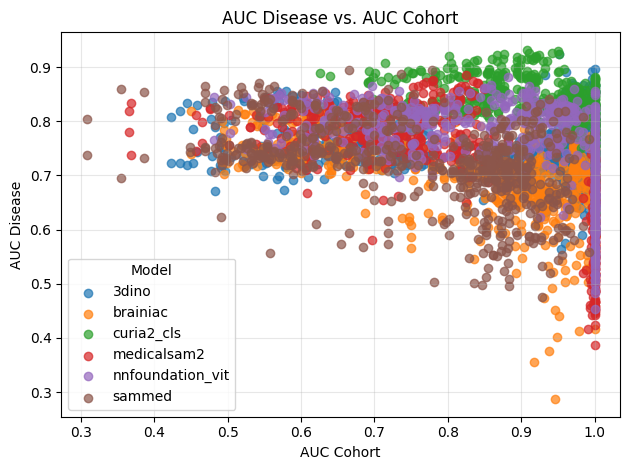

In [28]:
import matplotlib.pyplot as plt

for model, group in df_all.groupby("model"):
    plt.scatter(
        group["auc_cohort"],
        group["auc_disease"],
        label=model,
        alpha=0.7,
    )

plt.xlabel("AUC Cohort")
plt.ylabel("AUC Disease")
plt.title("AUC Disease vs. AUC Cohort")
plt.legend(title="Model")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

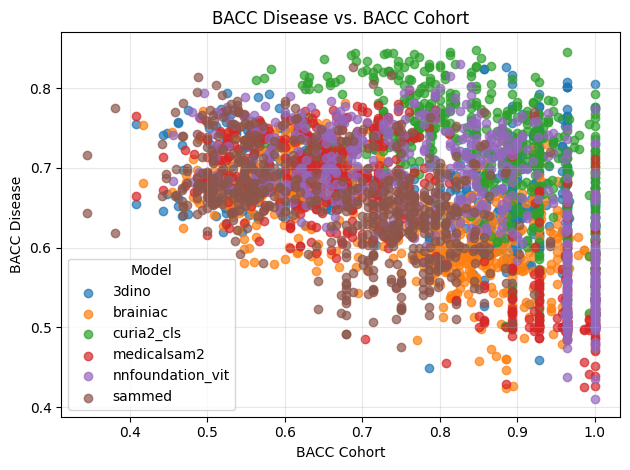

In [29]:
for model, group in df_all.groupby("model"):
    plt.scatter(
        group["bacc_cohort"],
        group["bacc_disease"],
        label=model,
        alpha=0.7,
    )

plt.xlabel("BACC Cohort")
plt.ylabel("BACC Disease")
plt.title("BACC Disease vs. BACC Cohort")
plt.legend(title="Model")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [30]:
metrics = ["auc_cohort", "auc_disease", "bacc_cohort", "bacc_disease", "auc_disease_internal", "wasserstein_rel", "mmd2", "frechet_dist", "jsd_manufacturer", "jsd_field_strength", "jsd_sex", "wasserstein_age", "jsd_label"]

summary = (
    df_all
    .groupby(["model", "train", "test"])[metrics]
    .agg(["mean", "std"])
)

# Flatten the MultiIndex columns: ("auc_cohort", "mean") -> "auc_cohort_mean"
summary.columns = [f"{col}_{stat}" for col, stat in summary.columns]
summary = summary.reset_index()

In [31]:
df_all.columns

Index(['i', 'model', 'train', 'test', 'auc_cohort', 'bacc_cohort',
       'acc_cohort', 'auc_disease', 'bacc_disease', 'acc_disease',
       'auc_disease_internal', 'bacc_disease_internal', 'acc_disease_internal',
       'disease_lr', 'wasserstein_dist', 'wasserstein_rel', 'mmd2',
       'frechet_dist', 'jsd_manufacturer', 'jsd_field_strength', 'jsd_sex',
       'jsd_age', 'wasserstein_age', 'jsd_label', 'combination'],
      dtype='object')

In [32]:
summary

,model,train,test,auc_cohort_mean,auc_cohort_std,auc_disease_mean,auc_disease_std,bacc_cohort_mean,bacc_cohort_std,bacc_disease_mean,...,jsd_manufacturer_mean,jsd_manufacturer_std,jsd_field_strength_mean,jsd_field_strength_std,jsd_sex_mean,jsd_sex_std,wasserstein_age_mean,wasserstein_age_std,jsd_label_mean,jsd_label_std
0,3dino,ADNI,AIBL,0.722507,0.043078,0.797335,0.012981,0.658667,0.030939,0.715416,...,0.265376,0.020588,0.020491,0.010703,0.002359,0.003504,1.072063,0.338800,0.071641,0.0
1,3dino,ADNI,BrainLAT,0.954560,0.015646,0.767144,0.019779,0.893000,0.026444,0.698917,...,0.254476,0.024755,0.007561,0.004883,0.007448,0.003350,4.491231,0.437986,0.012995,0.0
2,3dino,ADNI,NigerianBrain,0.982476,0.013173,0.670934,0.063941,0.909714,0.066043,0.594767,...,0.606074,0.016539,0.543935,0.019902,0.018097,0.008104,38.691518,0.474320,0.000626,0.0
3,3dino,ADNI,OASIS3,0.646596,0.039120,0.763202,0.016504,0.611667,0.033219,0.695084,...,0.252838,0.029027,0.122780,0.030888,0.002734,0.003177,4.360863,0.865420,0.037654,0.0
4,3dino,ADNI,OASIS4,0.538111,0.067524,0.819941,0.026510,0.525875,0.053594,0.745732,...,0.265236,0.026788,0.148769,0.026906,0.001220,0.001572,5.659877,0.423489,0.139354,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175,sammed,OASIS4,ADNI,0.520944,0.073197,0.735527,0.011438,0.504000,0.046524,0.654399,...,0.265236,0.026788,0.148769,0.026906,0.001220,0.001572,5.659877,0.423489,0.139354,0.0
176,sammed,OASIS4,AIBL,0.655139,0.067277,0.739869,0.011914,0.587875,0.058601,0.676706,...,0.000000,0.000000,0.065180,0.012756,0.000762,0.000845,5.056143,0.263212,0.383424,0.0
177,sammed,OASIS4,BrainLAT,0.880028,0.042010,0.687535,0.026710,0.800250,0.040887,0.588687,...,0.432296,0.007824,0.207263,0.009214,0.004578,0.001388,1.560925,0.119946,0.069534,0.0
178,sammed,OASIS4,NigerianBrain,0.918366,0.037579,0.744042,0.062243,0.825634,0.058096,0.649678,...,1.000000,0.000000,0.890218,0.000000,0.024393,0.000000,33.188014,0.000000,0.122141,0.0


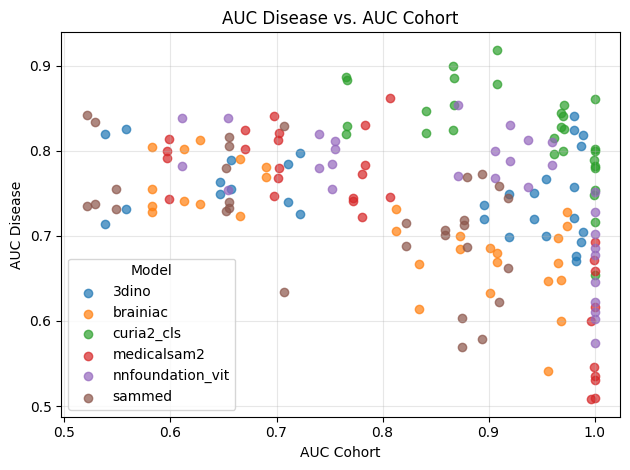

In [33]:
for model, group in summary.groupby("model"):
    plt.scatter(
        group["auc_cohort_mean"],
        group["auc_disease_mean"],
        label=model,
        alpha=0.7,
    )

plt.xlabel("AUC Cohort")
plt.ylabel("AUC Disease")
plt.title("AUC Disease vs. AUC Cohort")
plt.legend(title="Model")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [34]:
summary_no_nigerianbrain = summary[summary["test"] != "NigerianBrain"]
summary_no_nigerianbrain = summary_no_nigerianbrain[summary_no_nigerianbrain["train"] != "NigerianBrain"]


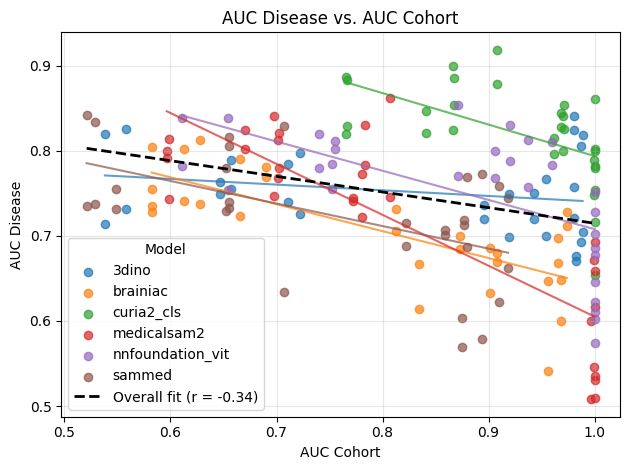

In [35]:
for model, group in summary.groupby("model"):
    x = group["auc_cohort_mean"].to_numpy()
    y = group["auc_disease_mean"].to_numpy()

    sc = plt.scatter(x, y, label=model, alpha=0.7)

    # Need at least 2 distinct x values to fit a line
    mask = np.isfinite(x) & np.isfinite(y)
    if mask.sum() >= 2 and np.unique(x[mask]).size >= 2:
        slope, intercept = np.polyfit(x[mask], y[mask], deg=1)
        xs = np.linspace(x[mask].min(), x[mask].max(), 100)
        plt.plot(xs, slope * xs + intercept,
                 color=sc.get_facecolor()[0], linewidth=1.5)
        
# Overall fit across all points
d = summary[["auc_cohort_mean", "auc_disease_mean"]].dropna()
slope, intercept = np.polyfit(d["auc_cohort_mean"], d["auc_disease_mean"], deg=1)
r = np.corrcoef(d["auc_cohort_mean"], d["auc_disease_mean"])[0, 1]

xs = np.linspace(d["auc_cohort_mean"].min(), d["auc_cohort_mean"].max(), 100)
plt.plot(xs, slope * xs + intercept, color="black", linestyle="--",
         linewidth=2, label=f"Overall fit (r = {r:.2f})")

plt.xlabel("AUC Cohort")
plt.ylabel("AUC Disease")
plt.title("AUC Disease vs. AUC Cohort")
plt.legend(title="Model")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [36]:
df_all.groupby(["model"]).agg({
    "auc_cohort": ["mean", "std"],
    "auc_disease": ["mean", "std"]})


auc_cohort           auc_disease          
                       mean       std        mean       std
model                                                      
3dino              0.830978  0.168540    0.751587  0.053363
brainiac           0.797050  0.154190    0.706530  0.076498
curia2_cls         0.925730  0.087946    0.821347  0.061391
medicalsam2        0.807034  0.155878    0.720549  0.111471
nnfoundation_vit   0.873881  0.137111    0.751266  0.086008
sammed             0.753490  0.153360    0.723908  0.076585

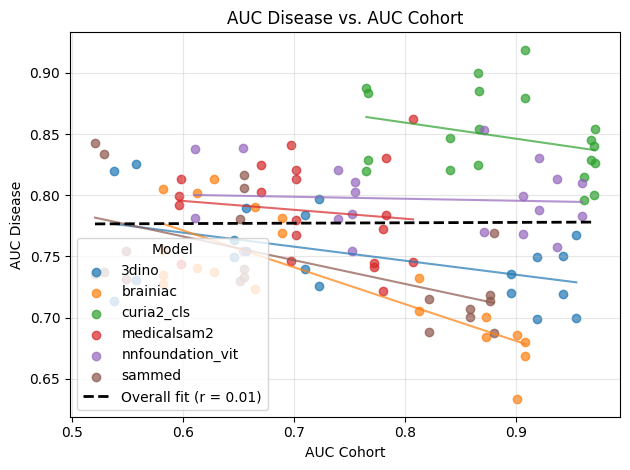

In [37]:
for model, group in summary_no_nigerianbrain.groupby("model"):
    x = group["auc_cohort_mean"].to_numpy()
    y = group["auc_disease_mean"].to_numpy()

    sc = plt.scatter(x, y, label=model, alpha=0.7)

    # Need at least 2 distinct x values to fit a line
    mask = np.isfinite(x) & np.isfinite(y)
    if mask.sum() >= 2 and np.unique(x[mask]).size >= 2:
        slope, intercept = np.polyfit(x[mask], y[mask], deg=1)
        xs = np.linspace(x[mask].min(), x[mask].max(), 100)
        plt.plot(xs, slope * xs + intercept,
                 color=sc.get_facecolor()[0], linewidth=1.5)
        
# Overall fit across all points
d = summary_no_nigerianbrain[["auc_cohort_mean", "auc_disease_mean"]].dropna()
slope, intercept = np.polyfit(d["auc_cohort_mean"], d["auc_disease_mean"], deg=1)
r = np.corrcoef(d["auc_cohort_mean"], d["auc_disease_mean"])[0, 1]

xs = np.linspace(d["auc_cohort_mean"].min(), d["auc_cohort_mean"].max(), 100)
plt.plot(xs, slope * xs + intercept, color="black", linestyle="--",
         linewidth=2, label=f"Overall fit (r = {r:.2f})")

plt.xlabel("AUC Cohort")
plt.ylabel("AUC Disease")
plt.title("AUC Disease vs. AUC Cohort")
plt.legend(title="Model")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

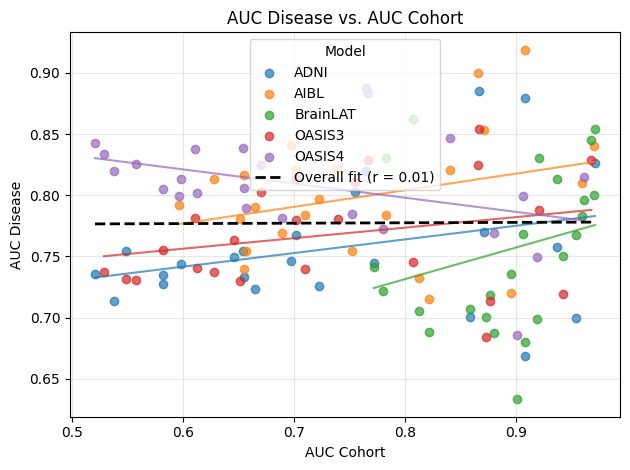

In [38]:
for model, group in summary_no_nigerianbrain.groupby("test"):
    x = group["auc_cohort_mean"].to_numpy()
    y = group["auc_disease_mean"].to_numpy()

    sc = plt.scatter(x, y, label=model, alpha=0.7)

    # Need at least 2 distinct x values to fit a line
    mask = np.isfinite(x) & np.isfinite(y)
    if mask.sum() >= 2 and np.unique(x[mask]).size >= 2:
        slope, intercept = np.polyfit(x[mask], y[mask], deg=1)
        xs = np.linspace(x[mask].min(), x[mask].max(), 100)
        plt.plot(xs, slope * xs + intercept,
                 color=sc.get_facecolor()[0], linewidth=1.5)
        
# Overall fit across all points
d = summary_no_nigerianbrain[["auc_cohort_mean", "auc_disease_mean"]].dropna()
slope, intercept = np.polyfit(d["auc_cohort_mean"], d["auc_disease_mean"], deg=1)
r = np.corrcoef(d["auc_cohort_mean"], d["auc_disease_mean"])[0, 1]

xs = np.linspace(d["auc_cohort_mean"].min(), d["auc_cohort_mean"].max(), 100)
plt.plot(xs, slope * xs + intercept, color="black", linestyle="--",
         linewidth=2, label=f"Overall fit (r = {r:.2f})")

plt.xlabel("AUC Cohort")
plt.ylabel("AUC Disease")
plt.title("AUC Disease vs. AUC Cohort")
plt.legend(title="Model")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [39]:
summary['combination'] = summary['model'] + '_' + summary['train'] + '_' + summary['test']

# Averaged

In [40]:
summary['model'].value_counts(dropna=False)

model
3dino               30
brainiac            30
curia2_cls          30
medicalsam2         30
nnfoundation_vit    30
sammed              30
Name: count, dtype: int64

In [41]:


# One-time install of the R packages (skipped if already present)
utils = importr("utils")
utils.chooseCRANmirror(ind=1)
for pkg in ["lme4", "lmerTest", "performance"]:
    if not isinstalled(pkg):
        utils.install_packages(pkg)

# --- Prepare data ---
cols = ["auc_disease_mean", "auc_cohort_mean", "model", "train", "test", "jsd_manufacturer_mean", "jsd_field_strength_mean", "jsd_sex_mean", "wasserstein_age_mean", "jsd_label_mean", "combination"]
data = summary[cols].dropna().copy()
for c in ["model", "train", "test", "combination"]:
    data[c] = data[c].astype(str)   # make sure grouping variables are treated as factors

with localconverter(ro.default_converter + pandas2ri.converter):
    r_df = ro.conversion.py2rpy(data)
ro.globalenv["dat"] = r_df

# --- Fit LMM in R ---
ro.r("""
suppressPackageStartupMessages({
  library(lmerTest)
  library(performance)
})
fit <- lmer(auc_disease_mean ~ auc_cohort_mean + (1 | model) + (1 | train) + (1 | test),
            data = dat)
""")

# --- Print results ---
print(ro.r("paste(capture.output(print(summary(fit))), collapse = '\n')")[0])
print(ro.r("paste(capture.output(print(r2_nakagawa(fit))), collapse = '\n')")[0])

# --- Optional: fixed effects and R² as pandas / floats ---
with localconverter(ro.default_converter + pandas2ri.converter):
    betas = ro.conversion.rpy2py(
        ro.r("as.data.frame(coef(summary(fit)))")
    )
r2 = ro.r("unlist(r2_nakagawa(fit))")
r2_marginal, r2_conditional = float(r2[1]), float(r2[0])

print(betas)
print(f"Marginal R2 (fixed effects only):      {r2_marginal:.3f}")
print(f"Conditional R2 (fixed + random):       {r2_conditional:.3f}")

R callback write-console: In addition:   
R callback write-console: Warning messages:
  
R callback write-console: 1:   
R callback write-console: In (function (package, help, pos = 2, lib.loc = NULL, character.only = FALSE,  :  
R callback write-console: 
   
R callback write-console:  library ‘/usr/lib/R/site-library’ contains no packages
  
R callback write-console: 2:   
R callback write-console: In (function (package, help, pos = 2, lib.loc = NULL, character.only = FALSE,  :  
R callback write-console: 
   
R callback write-console:  library ‘/usr/lib/R/site-library’ contains no packages
  
R callback write-console: 3:   
R callback write-console: In (function (package, help, pos = 2, lib.loc = NULL, character.only = FALSE,  :  
R callback write-console: 
   
R callback write-console:  library ‘/usr/lib/R/site-library’ contains no packages
  
R callback write-console: 4:   
R callback write-console: In (function (package, help, pos = 2, lib.loc = NULL, character.only = FALSE,  :  

Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: auc_disease_mean ~ auc_cohort_mean + (1 | model) + (1 | train) +  
    (1 | test)
   Data: dat

REML criterion at convergence: -511.5

Scaled residuals: 
     Min       1Q   Median       3Q      Max 
-2.94094 -0.51628 -0.03135  0.58064  2.80837 

Random effects:
 Groups   Name        Variance  Std.Dev.
 model    (Intercept) 0.0027008 0.05197 
 train    (Intercept) 0.0010717 0.03274 
 test     (Intercept) 0.0002886 0.01699 
 Residual             0.0025964 0.05096 
Number of obs: 180, groups:  model, 6; train, 6; test, 6

Fixed effects:
                Estimate Std. Error       df t value Pr(>|t|)    
(Intercept)      0.92118    0.04348 39.60338  21.187  < 2e-16 ***
auc_cohort_mean -0.21088    0.04165 63.95230  -5.063 3.74e-06 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Correlation of Fixed Effects:
            (Intr)
auc_chrt_mn -0.796
# R2 for Mixed Models

  Condi

In [42]:
summary_no_nigerianbrain['combination'] = summary_no_nigerianbrain['model'] + '_' + summary_no_nigerianbrain['train'] + '_' + summary_no_nigerianbrain['test']

In [43]:


# One-time install of the R packages (skipped if already present)
utils = importr("utils")
utils.chooseCRANmirror(ind=1)
for pkg in ["lme4", "lmerTest", "performance"]:
    if not isinstalled(pkg):
        utils.install_packages(pkg)

# --- Prepare data ---
cols = ["auc_disease_mean", "auc_cohort_mean", "model", "train", "test", "combination"]
data = summary_no_nigerianbrain[cols].dropna().copy()
for c in ["model", "train", "test", "combination"]:
    data[c] = data[c].astype(str)   # make sure grouping variables are treated as factors

with localconverter(ro.default_converter + pandas2ri.converter):
    r_df = ro.conversion.py2rpy(data)
ro.globalenv["dat"] = r_df

# --- Fit LMM in R ---
ro.r("""
suppressPackageStartupMessages({
  library(lmerTest)
  library(performance)
})
fit <- lmer(auc_disease_mean ~ auc_cohort_mean + (1 | model) + (1 | train) + (1 | test),
            data = dat)
""")

# --- Print results ---
print(ro.r("paste(capture.output(print(summary(fit))), collapse = '\n')")[0])
print(ro.r("paste(capture.output(print(r2_nakagawa(fit))), collapse = '\n')")[0])

# --- Optional: fixed effects and R² as pandas / floats ---
with localconverter(ro.default_converter + pandas2ri.converter):
    betas = ro.conversion.rpy2py(
        ro.r("as.data.frame(coef(summary(fit)))")
    )
r2 = ro.r("unlist(r2_nakagawa(fit))")
r2_marginal, r2_conditional = float(r2[1]), float(r2[0])

print(betas)
print(f"Marginal R2 (fixed effects only):      {r2_marginal:.3f}")
print(f"Conditional R2 (fixed + random):       {r2_conditional:.3f}")

R callback write-console: In addition:   
R callback write-console: Warning messages:
  
R callback write-console: 1:   
R callback write-console: In (function (package, help, pos = 2, lib.loc = NULL, character.only = FALSE,  :  
R callback write-console: 
   
R callback write-console:  library ‘/usr/lib/R/site-library’ contains no packages
  
R callback write-console: 2:   
R callback write-console: In (function (package, help, pos = 2, lib.loc = NULL, character.only = FALSE,  :  
R callback write-console: 
   
R callback write-console:  library ‘/usr/lib/R/site-library’ contains no packages
  
R callback write-console: 3:   
R callback write-console: In (function (package, help, pos = 2, lib.loc = NULL, character.only = FALSE,  :  
R callback write-console: 
   
R callback write-console:  library ‘/usr/lib/R/site-library’ contains no packages
  
R callback write-console: 4:   
R callback write-console: In (function (package, help, pos = 2, lib.loc = NULL, character.only = FALSE,  :  

Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: auc_disease_mean ~ auc_cohort_mean + (1 | model) + (1 | train) +  
    (1 | test)
   Data: dat

REML criterion at convergence: -496.6

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-1.9298 -0.6182 -0.0828  0.5231  3.1635 

Random effects:
 Groups   Name        Variance  Std.Dev.
 model    (Intercept) 0.0022749 0.04770 
 train    (Intercept) 0.0004642 0.02155 
 test     (Intercept) 0.0003497 0.01870 
 Residual             0.0005768 0.02402 
Number of obs: 120, groups:  model, 6; train, 5; test, 5

Fixed effects:
                Estimate Std. Error       df t value Pr(>|t|)    
(Intercept)      0.84634    0.03683 35.56308  22.977   <2e-16 ***
auc_cohort_mean -0.09010    0.03720 76.39125  -2.422   0.0178 *  
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Correlation of Fixed Effects:
            (Intr)
auc_chrt_mn -0.773
# R2 for Mixed Models

  Conditional R2:

In [44]:
df_all.to_csv(results_dir / "all.csv", index=False)